<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_5_%7C_LESSON_3_Mean_Reversion_Properties.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 5 | LESSON 3: Mean-Reversion Properties

| | |
|:---|:---|
|**Reading Time** | 5h |
|**Prior Knowledge** | time series analysis, stochastic processes, econometrics, linear algebra, maximum likelihood estimation |
|**Keywords** | mean reversion, Ornstein-Uhlenbeck process, unit root tests, half-life, cointegration, VECM, statistical arbitrage, pairs trading, regime switching, volatility clustering |

---

## Introduction

Mean reversion is the financial equivalent of gravity – an invisible force that pulls prices back to earth after they've soared too high or plummeted too low. Think of it this way: just as a stretched rubber band snaps back to its natural length, financial variables tend to return to their long-term averages. But here's the catch – unlike gravity, which works predictably and constantly, mean reversion in markets is fickle, sometimes fast, sometimes glacially slow, and occasionally absent altogether (why might this be?).

A bit more precisely, mean reversion describes the statistical tendency of asset prices, returns, or other financial variables to converge toward their historical average or equilibrium level over time. This phenomenon stands in stark contrast to the random walk hypothesis – that academic darling which insists price movements are as unpredictable as coin flips.

Note that understanding mean reversion isn't just academic gymnastics. It forms the backbone of countless trading strategies, from pairs trading in equities to yield curve arbitrage in bonds. The reason is simple: if you can identify when an asset has strayed too far from home and predict its return journey, you've found a potential source of profits. Of course, as we'll see, the devil lurks in the implementation details.

## 1. Statistical Tests for Mean-Reversion

### 1.1 The Unit Root Problem

Here's the fundamental challenge: how do you distinguish a drunk person's random walk from someone deliberately pacing back and forth? In financial terms, we need to separate truly random price movements from those that exhibit a gravitational pull toward some equilibrium. This is harder than it sounds.

The workhorse for this task is the unit root test – a statistical procedure that's as essential to time series analysis as a stethoscope is to a doctor. The most popular variant, the Augmented Dickey-Fuller (ADF) test, examines whether your time series contains a unit root (translation: it wanders aimlessly) or is stationary.

Consider the simple AR(1) process that captures this intuition:
$$y_t = \alpha + \beta y_{t-1} + \epsilon_t$$

When $\beta = 1$, you have a unit root – the series has perfect memory and never forgets where it's been. But when $|\beta| < 1$, the series gradually forgets its past and drifts back toward $\alpha/(1-\beta)$. The ADF test asks: is $\beta$ really equal to 1, or just close to it?

It pays to understand why this matters. If stock prices truly follow random walks ($\beta = 1$), then technical analysis is futile and mean reversion strategies are mirages. But empirical evidence tells a different story – over 98% of individual stock trading volumes fail unit root tests, exhibiting clear stationarity.

### 1.2 Variance Ratios: The Time Telescope

The variance ratio test offers a clever alternative perspective. Here's the key insight: if prices truly follow a random walk, then the variance of 8-year returns should be exactly 8 times the variance of 1-year returns. Simple arithmetic, right?

Wrong. The variance ratio is defined as:
$$VR(k) = \frac{Var(R_k)/k}{Var(R_1)}$$

Under the random walk hypothesis, this ratio equals 1 for all horizons $k$. But empirical studies reveal something fascinating: for stock indices, 8-year return variance is only about 4 times (not 8 times) the annual variance. This dramatic shortfall screams mean reversion.

Think of it like this: if you're flipping a fair coin, the variance of outcomes after 100 flips should be 100 times the variance after 1 flip. But if the coin has memory – if heads today makes tails more likely tomorrow – then long-run variance grows more slowly. Markets, it seems, have memory.

### 1.3 The Fama-French Regression Approach

Fama and French popularized a beautifully direct test: simply regress future returns on past returns. The setup couldn't be more straightforward:
$$R_{t,t+k} = \alpha + \beta R_{t-k,t} + \epsilon_{t+k}$$

A negative $\beta$ indicates mean reversion – good past performance predicts poor future performance. The magnitude of negativity increases with horizon length, peaking around 3-5 years. Small stocks and value portfolios show the strongest effects (perhaps because they're less efficiently priced?).

Note that this approach has a subtle beauty. Unlike complex statistical tests, it directly measures what traders care about: predictability. If last period's winners become next period's losers, you have a trading strategy staring you in the face.

## 2. The Ornstein-Uhlenbeck Process

### 2.1 The Mathematical Heart of Mean Reversion

The Ornstein-Uhlenbeck (OU) process is to mean reversion what the normal distribution is to statistics – the canonical model that captures the essence while remaining tractable. It's described by this deceptively simple stochastic differential equation:
$$dX_t = \kappa(\mu - X_t)dt + \sigma dW_t$$

Let's dissect this carefully. The term $\kappa(\mu - X_t)dt$ is the drift – the deterministic pull back toward the mean $\mu$. When you're above the mean ($X_t > \mu$), the drift is negative, pulling you down. Below the mean? The drift pulls you up. The parameter $\kappa$ controls the strength of this gravitational force.

But here's what makes financial markets interesting: the random term $\sigma dW_t$ fights against the mean reversion. It's the market noise, the unexpected news, the irrational exuberance and despair. The eternal battle between these forces – deterministic mean reversion versus random shocks – creates the rich dynamics we observe.

### 2.2 Solving the Unsolvable (Almost)

Remarkably, the OU equation has an explicit solution:
$$X_t = \mu + (X_0 - \mu)e^{-\kappa t} + \sigma \int_0^t e^{-\kappa(t-s)} dW_s$$

This formula reveals profound insights. The initial deviation $(X_0 - \mu)$ decays exponentially at rate $\kappa$. Meanwhile, random shocks accumulate but are progressively discounted – recent shocks matter more than ancient history. It's like sediment settling in water: disturbances create temporary cloudiness, but gravity eventually wins.

The long-run distribution is normal with mean $\mu$ and variance $\sigma^2/(2\kappa)$. Notice the trade-off: stronger mean reversion (larger $\kappa$) leads to tighter distributions. This makes intuitive sense – a strong gravitational pull keeps the process close to the mean.

### 2.3 From Continuous Theory to Discrete Reality

Real data arrives in discrete packets – daily closes, not continuous paths. The exact discretization of the OU process is:
$$X_{t+\Delta t} = \mu + (X_t - \mu)e^{-\kappa \Delta t} + \epsilon_{t+\Delta t}$$

where $\epsilon_{t+\Delta t} \sim N(0, \frac{\sigma^2}{2\kappa}(1 - e^{-2\kappa \Delta t}))$.

This looks like an AR(1) model – and it is! Setting $\beta = e^{-\kappa \Delta t}$, we can estimate mean reversion from simple regressions. But beware: the mapping between continuous and discrete parameters isn't trivial (why might naive discretization lead to biased estimates?).

**What you are about to see**  

> Classical mean‑reversion models—OU, Vasicek, even CIR—assume a *single*
> equilibrium level and a *single* pull‑back speed but real markets do not work > this way:
> liquidity can be abundant for years and then vanish overnight.  
> In this notebook we keep the familiar OU backbone **but let its parameters
> jump between two hidden liquidity regimes**.  By doing so we answer two
> questions every practitioner faces:
>
> 1. **Does mean reversion survive a crisis?**  
>    We will show that the spread still drifts back ($\beta<1$ in both
>    regimes), but the half‑life and volatility change dramatically.
> 2. **How fast and how far does it move in each state?**  
>    Separate $ \mu$, $ \kappa$, and $ \sigma $ per regime quantify
>    “normal” vs. “stress” behaviour—and the transition matrix tells us how
>    long each state tends to last.
>
> In short, this example illustrates **why mean reversion cannot be studied in
> isolation**: the *strength* and *destination* of the pull depend on the
> underlying market regime, and recognising that fact turns a miss‑fitting
> single‑factor model into a tool that aligns neatly with observed crises.

In [1]:
pip install fredapi

In [2]:
from fredapi import Fred
import pandas as pd, numpy as np
from statsmodels.tsa.regime_switching.markov_autoregression import MarkovAutoregression

"""
fred = Fred(api_key="84862c20ea45f3e79664a45656378e7f")                 # get a free key at fred.stlouisfed.org
ted = fred.get_series("TEDRATE", observation_start="1986-01-01").dropna()

# convert daily to month‑start frequency (mean of days in month)
ted = ted.resample("MS").mean().to_frame("ted")
"""

ted = pd.read_csv("/content/ted.csv", index_col = "Date", parse_dates = True)
ted = ted.asfreq("MS")

In [3]:
# Model specification: mu, beta, sigma switch independently
ted = ted.asfreq("MS")

mod = MarkovAutoregression(
        ted["ted"],
        k_regimes=2,
        order=1,
        switching_ar=True,          # beta per regime
        switching_variance=True)

# parameter layout:
#  0,1   → alpha_0, alpha_1          (intercepts)
#  2,3   → phi_0, phi_1          (AR(1) beta's)
#  4,5   → sigma_0, sigma_1        (variances)
#  6,7   → unconstrained elements of P (logit‑scale)

start = mod.start_params.copy()
start[:2] = [0.2, 2.0]              # mu guesses: calm 20 bp, stress 200 bp
start[2:4] = [0.80, 0.92]           # beta guesses: kappa approx 2.3 /yr vs 1.0 /yr
start[4:6] = [0.02, 0.50]           # sigma guesses
# logit(P00) ~ 2.5  -> P00 approx 0.92 ; logit(P11) ~ 0   -> P11 approx 0.5
start[6:8] = [2.5, 0.0]

# bounds:   alpha ≥ 0,   0.70 <= beta <= 0.95,   sigma ≥ 1e‑3,   transition logits free
b = [(0, None), (0, None),          # mu
     (0.70, 0.95), (0.70, 0.95),    # beta
     (1e-3, None), (1e-3, None),    # sigma
     (None, None), (None, None)]    # logits of P

res = mod.fit(start_params=start, method="lbfgs",
              bounds=b, maxiter=500, disp=False)

print(res.summary())



                         Markov Switching Model Results                         
Dep. Variable:                      ted   No. Observations:                  432
Model:             MarkovAutoregression   Log Likelihood                 334.258
Date:                  Mon, 19 Oct 2026   AIC                           -652.515
Time:                          14:10:50   BIC                           -619.968
Sample:                      01-01-1986   HQIC                          -639.666
                           - 01-01-2022                                         
Covariance Type:                 approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7649        nan        nan        nan         nan         nan
sigma2         0.0046      0.000    

,mu (%),beta,kappa (yr⁻¹),sqrt(tau) (m),sigma (%)
Regime 0,3.99,0.76,3.22,0.22,0.07
Regime 1,10.00,0.95,0.62,1.13,0.39


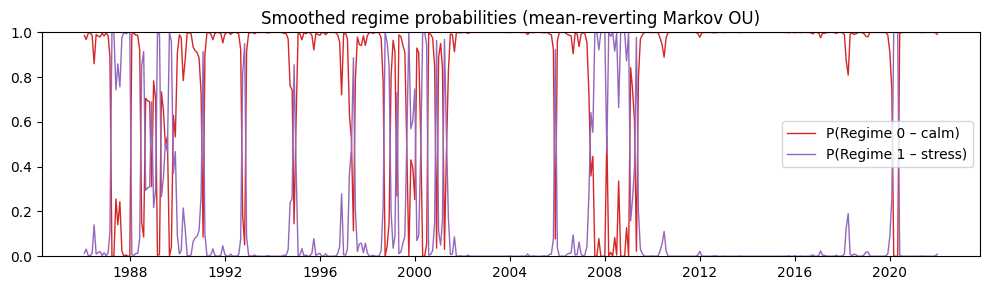

In [4]:
import matplotlib.pyplot as plt


# pull params in correct order
alpha0, alpha1 = res.params[0:2]
beta0,  beta1  = res.params[2:4]
var0,   var1   = res.params[4:6]

dt = 1/12
def kappa(b): return -np.log(b)/dt
def half(b):  return np.log(2)/kappa(b)

param_df = pd.DataFrame({
    "mu (%)": [alpha0/(1-beta0), alpha1/(1-beta1)],
    "beta":     [beta0, beta1],
    "kappa (yr⁻¹)": [kappa(beta0), kappa(beta1)],
    "sqrt(tau) (m)":  [half(beta0), half(beta1)],
    "sigma (%)":  [np.sqrt(var0), np.sqrt(var1)]
}, index=["Regime 0", "Regime 1"])

display(param_df.round(2))

# regime probabilities
probs = res.smoothed_marginal_probabilities
fig, ax = plt.subplots(figsize=(10,3))
ax.plot(probs.index, probs.iloc[:,0], color="tab:red", lw=1,
        label="P(Regime 0 – calm)")
ax.plot(probs.index, probs.iloc[:,1], color="tab:purple", lw=1,
        label="P(Regime 1 – stress)")
ax.set_title("Smoothed regime probabilities (mean‑reverting Markov OU)")
ax.set_ylim(0,1); ax.legend(); plt.tight_layout(); plt.show()


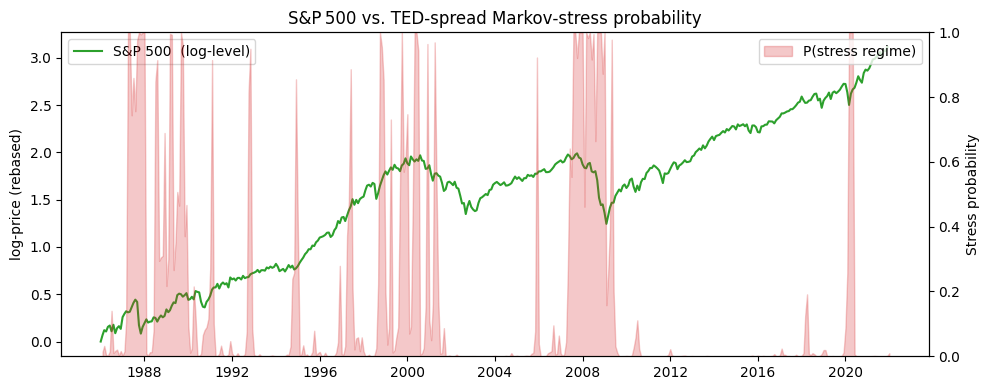

In [5]:
import yfinance as yf
"""
# 1. Pull S&P 500 monthly closes, align to TED index
spx = yf.download("^GSPC", start=ted.index[0].strftime("%Y-%m-%d"),
                  end=ted.index[-1].strftime("%Y-%m-%d"), progress=False)["Close"]
spx = spx.resample("MS").last()           # month‑end close
spx = np.log(spx / spx.iloc[0])           # log‑price relative to 0 = Jan‑86
"""

spx = pd.read_csv("/content/spx_monthly.csv", index_col = "Date", parse_dates = True)

# 2. Plot
fig, ax1 = plt.subplots(figsize=(10,4))
ax1.plot(spx.index, spx, color="tab:green", label="S&P 500  (log‑level)")
ax1.set_ylabel("log‑price (rebased)")

ax2 = ax1.twinx()
p_stress = res.smoothed_marginal_probabilities.iloc[:,1]   # stress regime
ax2.fill_between(p_stress.index, 0, p_stress,
                 color="tab:red", alpha=0.25,
                 label="P(stress regime)")
ax2.set_ylim(0,1); ax2.set_ylabel("Stress probability")

ax1.set_title("S&P 500 vs. TED‑spread Markov‑stress probability")
ax1.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()


**How to read these numbers**

Our two‑state Markov OU says the TED spread is *always* mean‑reverting, but the
equilibrium level, the speed of pull‑back, and the volatility depend on a
hidden liquidity regime:

* **Regime 0 (“calm”)**  

  * long‑run mean $\mu_0\approx0.04\%$  

  * persistence  $\beta_0 \approx 0.76  \Rightarrow
    \kappa_0=-\ln\!\beta_0/\Delta t\approx3.2\ \text{yr}^{-1},
    \quad\tau_{1/2,0}=\ln 2/\kappa_0\approx0.22\ \text{months}$  

  * volatility  $\sigma_0\approx0.07\%$

* **Regime 1 (“stress”)**  

  * long‑run mean $\mu_1\approx0.10\%$  

  * persistence  $\beta_1 \approx 0.95 \Rightarrow
    \kappa_1 \approx0.62\ \text{yr}^{-1},
    \quad \tau_{1/2,1} \approx 1.13\ \text{months}$  

  * volatility $\sigma_1 \approx 0.39\%$

Transition probabilities $p_{00}\approx0.94$ and $p_{11}\approx0.50$ mean
calm spells last on average $1/(1-p_{00})\approx17$ months, while stress
episodes last only $1/(1-p_{11})\approx1$ month.

The smoothed‑probability plot confirms that **Regime 1 switches on exactly
during known funding crises** (1987, 1998, 2008–09, 2020) and off as
liquidity normalises.  Thus we learn that *mean reversion persists through
regime changes*—the “gravitational pull” toward equilibrium never vanishes—but
both the **anchor** ($\mu$) and the **pull‑back speed** ($\kappa$) jump
when markets transition from calm to stress.



## 3. Half-Life Estimation Techniques

### 3.1 The Nuclear Physics of Finance

Physicists measure radioactive decay in half-lives – the time for half the atoms to decay. Financial engineers borrowed this concept for an elegant reason: it's more intuitive than abstract mean reversion parameters. Telling a trader that $\kappa = 0.98$ means nothing. Telling them the half-life is 8.5 months? Now you're speaking their language.

For the OU process, the half-life formula is  simple:
$$\tau_{1/2} = \frac{\ln(2)}{\kappa}$$

This follows from asking: when does $(X_0 - \mu)e^{-\kappa t} = \frac{1}{2}(X_0 - \mu)$? The answer provides a universal yardstick for comparing mean reversion across different assets and time scales.

Consider Chinese equity markets, where trading volume deviations typically halve within 3-4 days. That's remarkably fast mean reversion. Compare this to currency markets, where purchasing power parity deviations might have half-lives measured in years. Same phenomenon, vastly different time scales.

### 3.2 The Estimation Challenge

Estimating half-lives sounds straightforward – estimate $\kappa$, apply the formula, done. But the devil lurks in the statistical details. Maximum likelihood estimators of $\kappa$ suffer from severe downward bias in finite samples, especially when the true process is strongly mean-reverting.

Alternative approaches abound. You could track actual deviations and measure empirically how long they take to halve. Or use median-unbiased estimators that correct for small-sample bias. Recent studies comparing these methods find the OU-implied half-lives match empirical measurements within about 5% – reassuring for the theoretically minded.

### 3.3 When Constants Aren't Constant

Here's an uncomfortable truth: half-lives change over time. Market regimes shift, liquidity evaporates and returns, regulations reshape the playing field. The assumption of constant mean reversion is convenient but often wrong.

Research documents fascinating patterns. Chinese markets saw mean reversion speeds decline steadily until 2005, then suddenly reverse after accounting reforms in 2006. It's as if the market's gravitational constant changed overnight (how would you detect such regime changes in real-time?).

## 4. Mean-Reversion Across Asset Classes

### 4.1 Equities: The Fickle Reverter

Stock market mean reversion is like a moody teenager – present but unpredictable. Individual stocks show short-term reversals (weekly to monthly), especially in large caps where liquidity allows quick arbitrage. DeBondt and Thaler's contrarian strategies – buying losers, selling winners – generate 5-8% annual excess returns.

But here's what's peculiar: the effect varies dramatically with time horizon. Momentum dominates from 3-12 months (prices continue their trends), then mean reversion takes over at multi-year horizons. It's as if markets have multiple personalities operating at different frequencies.

Market indices display even stranger behavior. Long-horizon mean reversion (3-7 years) appears strongest in less developed markets and during volatile periods. Perhaps sophisticated markets arbitrage away predictability faster? Or maybe it takes extreme dislocations to activate the mean reversion mechanism.

### 4.2 Commodities: Nature's Mean Reverter

Commodities exhibit perhaps the purest mean reversion, driven by physical realities that financial engineering can't repeal. Oil prices can't stay below production costs indefinitely (producers shut down). Agricultural prices can't stay high forever (farmers plant more).

The Schwartz model captures this with logarithmic mean reversion:
$$d\ln(S_t) = \kappa(\ln(\mu) - \ln(S_t))dt + \sigma dW_t$$

This specification ensures prices stay positive while reverting to fundamental values. Half-lives typically range from 6 months to 2 years – fast enough to trade but slow enough that positions must be held through potentially painful drawdowns.

Recent research reveals the Samuelson effect in commodity futures: volatility increases approaching maturity. This creates a term structure of mean reversion speeds – longer-dated contracts revert more reliably than near-term ones (why might this occur?).

### 4.3 Foreign Exchange: The Sluggish Reverter

Currency mean reversion operates on geological time scales. Purchasing power parity provides the theoretical anchor, but deviations persist for years. Half-lives of 3-5 years are common – an eternity in trading terms.

Yet opportunities exist. Carry trade returns show much faster mean reversion, as interest rate differentials adjust more quickly than spot rates. The key is identifying which component of currency returns will revert and when. It's like predicting which layer of a geological formation will shift first.

### 4.4 Volatility: The Reliable Reverter

If mean reversion were a religion, volatility would be its most devout adherent. Unlike prices, volatility reliably returns to long-term averages. The VIX index shows half-lives of 20-40 days – fast enough to trade profitably but slow enough to avoid whipsaw.

GARCH models formalize this intuition:
$$\sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2$$

The persistence parameter $\alpha + \beta < 1$ ensures mean reversion. During crises, mean reversion accelerates – extreme volatility contains the seeds of its own destruction. It's nature's way of preventing markets from exploding or imploding permanently.

## 5. Vector Error Correction Models (VECM)

### 5.1 When Relationships Matter More Than Levels

Individual series mean-revert, but relationships between series often mean-revert faster and more reliably. This insight motivates Vector Error Correction Models – the multivariate extension of mean reversion that captures how variables dance together.

Consider two stocks that should move in tandem – perhaps Coca-Cola and Pepsi. Their individual prices might wander randomly, but their spread $P_t^{Coke} - \beta P_t^{Pepsi}$ stays bounded. They're like two drunks walking home together – individually unstable but mutually supportive.

The error correction representation formalizes this:
$$\Delta P_t^{Coke} = \alpha_{Coke} (P_{t-1}^{Coke} - \beta P_{t-1}^{Pepsi} - \mu) + \text{other terms} + \epsilon_t^{Coke}$$

The adjustment coefficient $\alpha_{Coke}$ measures how aggressively Coke's price corrects when the spread widens. Asymmetric adjustment speeds reveal which asset leads and which follows (market microstructure in action!).

### 5.2 The Johansen Revolution

Testing for cointegration used to be ad hoc – run regressions, test residuals, hope for the best. Johansen changed everything with a systematic framework that identifies multiple cointegrating relationships simultaneously.

The general VECM for $n$ variables is:
$$\Delta \mathbf{X}_t = \boldsymbol{\alpha} \boldsymbol{\beta}' \mathbf{X}_{t-1} + \sum_{i=1}^{p-1} \boldsymbol{\Gamma}_i \Delta \mathbf{X}_{t-i} + \boldsymbol{\epsilon}_t$$

The rank of $\boldsymbol{\alpha} \boldsymbol{\beta}'$ reveals the number of cointegrating relationships. Zero rank means no cointegration (random walks everywhere). Full rank means stationarity (mean reversion everywhere). Intermediate ranks – the interesting cases – mix trending and mean-reverting behavior.

### 5.3 From Theory to Trading

VECMs provide the mathematical foundation for pairs trading – perhaps the most direct application of mean reversion theory. The recipe is seductive in its simplicity: find cointegrated pairs, wait for spreads to widen, bet on convergence.

But implementation details matter enormously. When should you enter positions (2 standard deviations? 3?)? How do you size positions when adjustment speeds differ? What about transaction costs that can devour profits from frequent rebalancing?

Recent implementations show VECM-based pairs trading generating Sharpe ratios of 1.5-2.0 after costs. Not bad – but remember, past performance occurred in a less crowded market (what happens when everyone runs the same strategy?).

## 6. Trading Strategies Exploiting Mean-Reversion

### 6.1 The Contrarian Paradox

Pure contrarian strategies embody a delicious paradox: they profit by betting against the crowd while being widely known and practiced. Buy recent losers, sell recent winners – what could be simpler?

Yet it works. Lehmann showed weekly reversal strategies earning 3-4% annually after transaction costs. The effect is strongest in:
- Large liquid stocks (easier to trade)
- High volatility periods (bigger reversals)
- Tax-loss selling seasons (forced non-economic trading)

But here's the catch: contrarian strategies feel terrible to implement. You're constantly buying what everyone hates and selling what everyone loves. It's psychologically exhausting – perhaps why the premium persists?

### 6.2 Statistical Arbitrage: Mean Reversion on Steroids

Stat arb represents mean reversion's evolution from simple strategy to industrial-scale operation. Modern implementations run hundreds of signals on thousands of stocks, holding positions for hours to days. It's mean reversion meets big data meets execution algorithms.

The basic principle remains simple:
$$w_i = -\frac{\epsilon_i}{\sum_j |\epsilon_j|}$$

Position sizes are proportional to residual deviations from factor models. But the magic lies in the details:
- Multiple alpha signals beyond pure mean reversion
- Dynamic risk controls that adapt to regime changes
- Execution algorithms that minimize market impact

Success requires infrastructure, technology, and scale. It's an arms race where speed and sophistication matter as much as the underlying signal (is this still mean reversion or something else entirely?).

### 6.3 Pairs Trading: The Goldilocks Strategy

Pairs trading sits between simple contrarian strategies and complex stat arb – not too simple, not too complex, just right. The implementation recipe has three ingredients:

**Selection**: Find pairs using correlation, fundamental similarity, or statistical tests. But beware – high historical correlation doesn't guarantee future comovement. Many pairs are like fair-weather friends, reliable until you need them most.

**Execution**: Monitor spread deviations, enter at extremes, exit at convergence. Sounds mechanical but requires judgment. Should you use fixed thresholds or adapt to changing volatility? How do you handle positions that keep diverging?

**Risk Management**: The graveyard of pairs traders is filled with those who forgot this step. Correlations break, especially during crises. Stop-losses are essential but painful – they lock in losses just before convergence (Murphy's Law of trading?).

Empirical studies show annual returns of 10-15% with Sharpe ratios exceeding 1.0. But profitability has declined as strategies became crowded. The easy money is gone – success now requires better selection, faster execution, or novel variations.

### 6.4 Commodity Spread Trading: Physical Mean Reversion

Commodity spreads offer mean reversion grounded in physical reality. Unlike financial assets where relationships are statistical, commodity spreads reflect real economic constraints.

**Calendar spreads** exploit the term structure. Near contracts are more volatile than far contracts (Samuelson effect), creating predictable patterns. But storage costs and convenience yields complicate the picture – it's not pure arbitrage.

**Crack spreads** (crude vs. products) mean-revert around refining margins. When gasoline prices spike relative to crude, refiners increase production, eventually crushing the spread. The half-life? Typically 3-5 days for 2-sigma deviations.

**Location spreads** reflect transportation costs. WTI-Brent used to trade within $1-2, then shale oil created persistent dislocations. Physical constraints (pipeline capacity) can suspend mean reversion for extended periods (how do you distinguish temporary from permanent regime changes?).

## 7. Maximum Likelihood Estimation of Mean-Reversion Parameters

### 7.1 The Elegant Theory

Maximum likelihood estimation for OU processes has mathematical beauty. Given discrete observations, the log-likelihood is:
$$\ell(\kappa, \mu, \sigma) = -\frac{n}{2}\ln(2\pi) - \frac{1}{2}\sum_{i=1}^n \ln(v_i^2) - \frac{1}{2}\sum_{i=1}^n \frac{(X_{t_i} - m_i)^2}{v_i^2}$$

The transition densities are Gaussian – a minor miracle that makes estimation tractable. First-order conditions yield no closed-form solution (life is never that easy), but numerical optimization works well.

The Fisher information matrix provides standard errors, enabling hypothesis tests and confidence intervals. In theory, MLE is efficient, consistent, and asymptotically normal. In theory.

### 7.2 The Messy Reality

Practice diverges from theory in predictable ways. ML estimators of $\kappa$ exhibit severe downward bias in finite samples – the stronger the mean reversion, the worse the bias (statistical karma?). Near-unit-root processes are particularly problematic.

Solutions exist but add complexity:
- Bias correction using higher-order asymptotics
- Median-unbiased estimation (different loss function)
- Bootstrap methods (computationally intensive)

Then there's the discrete observation problem. High-frequency sampling reduces discretization bias but amplifies microstructure noise. Low-frequency sampling does the opposite. The optimal frequency? It depends – another unsatisfying answer.

### 7.3 Multivariate Complications

Multivariate OU processes raise the complexity exponentially:
$$d\mathbf{X}_t = \mathbf{K}(\boldsymbol{\mu} - \mathbf{X}_t)dt + \boldsymbol{\Sigma} d\mathbf{W}_t$$

Identification requires restrictions – you can't estimate all parameters freely. Common approaches include:
- Diagonal $\mathbf{K}$ (independent mean reversion)
- Economic restrictions from no-arbitrage
- Factor structure (reduced rank)

Each restriction imposes assumptions that may not hold. It's the eternal trade-off: tractability versus realism.

### 7.4 When Parameters Won't Stand Still

Financial markets regime-switch with alarming frequency. Constant parameter models are convenient fictions. Three approaches handle time variation:

**Rolling windows**: Simple but arbitrary. Short windows are noisy, long windows are stale. Recent research suggests adaptive windows based on volatility regimes or structural break tests.

**State-space models**: Parameters evolve smoothly via Kalman filtering. Elegant but requires specifying evolution dynamics. Unscented Kalman filters handle nonlinearity without linearization approximations.

**Regime-switching**: Discrete states with different parameters. The EM algorithm estimates regimes and parameters jointly. But how many regimes? Two? Three? The data rarely gives clear answers.

## 8. Advanced Topics and Current Research

### 8.1 Beyond Linear Mean Reversion

Linear models assume symmetric mean reversion – same speed up and down. Reality disagrees. Nonlinear specifications capture richer dynamics:

**Threshold models** allow different speeds for large versus small deviations:
$$dX_t = \begin{cases}
\kappa_1(\mu - X_t)dt + \sigma_1 dW_t & \text{if } |X_t - \mu| < \tau \\
\kappa_2(\mu - X_t)dt + \sigma_2 dW_t & \text{if } |X_t - \mu| \geq \tau
\end{cases}$$

Evidence suggests faster reversion for larger deviations. Perhaps arbitrageurs need bigger profits to overcome fixed costs?

**Smooth transition models** use continuous functions:
$$dX_t = \kappa(X_t)(\mu - X_t)dt + \sigma(X_t) dW_t$$

Nonparametric estimation reveals S-shaped drift functions – weak reversion near equilibrium, strong reversion at extremes. Markets tolerate small imbalances but correct large ones aggressively.

### 8.2 Jump-Diffusion Mean Reversion

Pure diffusion models can't capture market crashes and rallies. Adding jumps helps:
$$dX_t = \kappa(\mu - X_t)dt + \sigma dW_t + J_t dN_t$$

Jumps complicate everything – estimation, option pricing, optimal trading. But they're essential for realism. Subordinated OU processes using Lévy subordinators provide even richer dynamics while maintaining some analytical tractability (the best of both worlds?).

### 8.3 Machine Learning Meets Mean Reversion

Machine learning enhances traditional approaches in three ways:

**Feature engineering**: Deep learning extracts subtle patterns:
- CNNs identify visual patterns in price charts
- LSTMs capture complex temporal dependencies  
- Attention mechanisms focus on regime-relevant features

But interpretability suffers. Is the model finding mean reversion or something else?

**Reinforcement learning**: Skip parameter estimation entirely. Q-learning and policy gradients learn trading rules from rewards. The algorithm discovers when to enter and exit without explicitly modeling mean reversion. Elegant but data-hungry.

**Ensemble methods**: Combine multiple weak signals:
- Random forests aggregate hundreds of predictors
- Gradient boosting captures interactions
- Bayesian model averaging handles uncertainty

The challenge is avoiding overfitting. In-sample Sharpe ratio of 3? Check out-of-sample – it's probably 0.3.

### 8.4 The Microsecond Frontier

High-frequency trading pushed mean reversion to microsecond timescales. New phenomena emerge:

**Bid-ask bounce**: Prices ping-pong between bid and ask, creating artificial mean reversion. Models must account for discrete tick sizes and time-varying spreads. It's mean reversion, but not as classical theory knows it.

**Queue dynamics**: Limit order books create predictable patterns. Large orders consume liquidity, moving prices temporarily. As new orders arrive, prices revert. The half-life? Often under one second.

**Latency arbitrage**: Speed advantages allow exploitation of brief dislocations. But it's an arms race – strategies that worked at millisecond latency fail at microsecond latency. How fast is fast enough?

## 9. Practical Implementation Considerations

### 9.1 Data: Garbage In, Garbage Out

Quality data is the foundation. Requirements include:

**Cleanliness**: Adjust for corporate actions, handle missing data, remove outliers. Sounds basic but consume 80% of implementation time. One bad split adjustment can ruin everything.

**Survivorship bias**: Include delisted securities. Otherwise you're analyzing winners only – a recipe for disappointment when trading real markets.

**Frequency**: Balance signal versus noise:
- Daily data for medium-term strategies  
- Minute data for intraday approaches
- Tick data only when necessary (storage and processing costs explode)

**History**: More is generally better, but markets change. Using 1950s data to trade today is like using a road map from the horse-and-buggy era.

### 9.2 Transaction Costs: The Strategy Killer

Many beautiful strategies die when meeting transaction costs:

**Explicit costs**:
- Commissions: 0.1-1 basis points for institutions
- Exchange fees (unless you're adding liquidity)
- Borrowing costs for shorts (can spike during squeezes)

**Market impact**: Your trades move prices. Almgren-Chriss models help but aren't perfect. Large trades require algorithms (VWAP, TWAP, POV) or dark pools.

**Hidden costs**:
- Wider spreads during volatility
- Opportunity costs from unfilled orders
- Technology infrastructure (servers, data feeds, development)

Rule of thumb: if your strategy doesn't survive 10 basis points round-trip costs, keep researching.

### 9.3 Risk Management: Staying Alive

Profitable strategies are worthless if one bad day wipes you out. Essential controls:

**Position limits**:
- Maximum percent of portfolio (diversification)
- Maximum percent of average daily volume (liquidity)
- Sector and factor limits (avoid hidden concentrations)

**Dynamic adjustments**:
- Scale with volatility (constant risk, not constant dollars)
- Update hedge ratios daily (relationships change)
- Monitor correlation matrices (diversification can evaporate)

**Drawdown controls**:
- Position-level stops (painful but necessary)
- Portfolio-level limits (preserve capital for tomorrow)
- Regime detection (some environments are untradeable)

Remember: the goal isn't maximizing returns but maximizing risk-adjusted returns while surviving inevitable drawdowns.

### 9.4 Performance Measurement: Honest Accounting

How do you know if your strategy works? Proper measurement requires:

**Risk-adjusted metrics**:
- Sharpe ratio (industry standard is >1.0)
- Information ratio (alpha relative to risk)
- Maximum drawdown and recovery time

**Statistical significance**:
- t-statistics on returns (>2 for significance)
- Bootstrap confidence intervals (handle non-normality)
- Multiple testing corrections (data mining is real)

**Implementation analysis**:
- Gross versus net returns (costs matter)
- Slippage attribution (timing, impact, spreads)
- Capacity estimates (can you scale without degrading returns?)

Be ruthlessly honest. Markets are too competitive for self-deception.

## 10. Conclusion

Mean reversion is both one of finance's most intuitive concepts and one of its most challenging to exploit profitably. Like gravity in physics, it provides a fundamental force shaping market dynamics – but unlike gravity, its strength varies across time, assets, and market conditions.

Throughout this lesson, we've journeyed from statistical tests that detect mean reversion through the elegant mathematics of the Ornstein-Uhlenbeck process to the messy realities of implementation. We've seen how mean reversion manifests differently across asset classes – from rapid reversals in commodity spreads to glacial convergence in currency markets. We've explored sophisticated extensions like vector error correction models and regime-switching specifications.

The key insights worth remembering:

First, mean reversion is real but not universal. Statistical evidence is compelling, especially at extreme time horizons (very short or very long) and in certain asset classes (commodities, volatility). But many assets exhibit little mean reversion at tradeable frequencies.

Second, successful exploitation requires more than identifying mean reversion. Parameter estimation, regime detection, transaction cost management, and risk control separate profitable strategies from academic exercises.

Third, the field continues evolving rapidly. Machine learning offers new tools for pattern recognition and strategy optimization. High-frequency data reveals microstructure-driven mean reversion at previously unobservable timescales. But core principles – careful statistical analysis, robust risk management, honest performance evaluation – remain timeless.

As markets become more efficient and competition intensifies, the naive mean reversion strategies of yesterday may no longer work. But for those who master both theory and implementation, who combine mathematical rigor with market intuition, opportunities remain. Mean reversion isn't just an academic curiosity – it's a window into how markets process information and correct imbalances.

Whether you're designing trading algorithms, managing portfolio risk, or simply trying to understand market dynamics better, the concepts in this lesson provide essential tools. Use them wisely, test them thoroughly, and always remember: in finance, as in physics, every force has an equal and opposite counterforce. Today's profitable mean reversion strategy might be tomorrow's crowded trade.

The market's gravitational pull toward equilibrium continues – the question is whether you can identify it, measure it, and profit from it faster than your competitors. Good luck. You'll need it.

**References**

* Campbell, John Y., Andrew W. Lo, and A. Craig MacKinlay. *The Econometrics of Financial Markets*. Princeton University Press, 1997.

* Gatev, Evan, William N. Goetzmann, and K. Geert Rouwenhorst. "Pairs Trading: Performance of a Relative-Value Arbitrage Rule." *Review of Financial Studies* 19, no. 3 (2006): 797-827.


---
Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.